In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import glob

from micom import load_pickle
from micom.qiime_formats import load_qiime_model_db, load_qiime_medium
from micom.workflows import grow, save_results, load_results
from micom.viz import *
from micom.measures import *

cmap = sns.color_palette("coolwarm_r", as_cmap=True)

In [2]:
taxa = [
    'B_caccae',
    'B_cellulosilyticus_WH2',
    'B_ovatus',
    'B_thetaiotaomicron',
    'B_uniformis',
    'B_vulgatus',
    'C_aerofaciens',
    'C_scindens',
    'C_spiroforme',
    'P_distasonis',
    'R_obeum'
    ]

pretty_names_dir = {
    'B_caccae': 'Bca',
    'B_cellulosilyticus_WH2': 'Bce',
    'B_ovatus': 'Bov',
    'B_thetaiotaomicron': 'Bth',
    'B_uniformis': 'Bun',
    'B_vulgatus': 'Bvu',
    'C_aerofaciens': 'Cae',
    'C_scindens': 'Csc',
    'C_spiroforme': 'Csp',
    'P_distasonis': 'Pdi',
    'R_obeum': 'Rob',
    }

# HF0

In [3]:
diet = load_qiime_medium("media/vmh_unhealthy.qza")
ko_log_foldchange = []
for file_path in glob.glob("models/Community/hf0/*.pickle"):
    name = file_path.split("/")[-1].split(".")[0]
    com = load_pickle(file_path)
    com.medium = diet.flux
    ko_new, ko_old = com.knockout_taxa(fraction=0.6, method='raw', diag=False)
    ko_old = ko_old.drop('medium', axis=0)
    old = np.zeros(ko_new.shape)
    for ko in range(len(ko_new.index)):
        for taxa in range(len(ko_old.index)):
            old[ko, taxa] = ko_old.iloc[taxa]
            if ko == taxa:
                old[ko, taxa] = np.nan
    old = pd.DataFrame(old, index=ko_new.index, columns=ko_old.index)
    ko_log_foldchange.append(-(np.log10(ko_new+1e-6) - np.log10(old+1e-6)))

Set parameter Username
Academic license - for non-commercial use only - expires 2024-10-23
Read LP format model from file /tmp/tmpda8a8ivy.lp
Reading time = 0.22 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmpygr2uzkq.lp
Reading time = 0.14 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmp2et2yfl7.lp
Reading time = 0.12 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

... (6 outputs left out)

Read LP format model from file /tmp/tmprc2ff1pd.lp
Reading time = 0.11 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmp8iwdbx__.lp
Reading time = 0.11 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

In [4]:
ko_log_foldchange_mean = pd.DataFrame(
    np.mean(ko_log_foldchange, axis=0), 
    columns=ko_log_foldchange[0].columns, 
    index=ko_log_foldchange[0].index
    )
ko_log_foldchange_mean.index.name = 'Knockout species'
ko_log_foldchange_mean.columns.name = 'Species'
ko_log_foldchange_mean.to_csv("results/hf0/knockouts/ko_foldchange_mean.tsv", sep="\t")
ko_log_foldchange_mean.columns = ko_log_foldchange_mean.columns.map(pretty_names_dir)
ko_log_foldchange_mean.index = ko_log_foldchange_mean.index.map(pretty_names_dir)
ko_log_foldchange_mean

Species,Bca,Bce,Bov,Bth,Bun,Bvu,Cae,Csc,Csp,Pdi,Rob
Knockout species,,,,,,,,,,,
Bca,NaN,-2.161329,-2.005716,-2.372893,-1.893141,-0.129611,-2.073720,-1.992653,-2.086696,-2.561492,-2.201495
Bce,0.368649,NaN,-0.467288,-0.026368,-0.441671,-0.111249,-0.356858,-0.526093,-0.199694,-0.106844,-0.437817
Bov,1.596293,-0.966856,NaN,-0.414588,0.147637,0.008776,0.007960,-0.051035,-0.058628,-0.493796,-0.013049
Bth,-0.279394,0.099438,-0.160195,NaN,-0.028130,-0.002785,-0.318935,-0.198878,-0.944190,-3.070448,-0.308736
Bun,0.372645,0.257303,-0.043651,0.628084,NaN,1.903659,-0.230033,-0.093928,-0.735134,0.232814,-0.252260
Bvu,1.021191,-0.009517,-0.141153,-4.276167,-0.679832,NaN,-0.247798,-0.168007,-0.503033,-3.791187,-0.246638
Cae,0.668611,-0.220163,0.076137,-0.714616,0.185431,0.003661,NaN,0.012921,-0.322033,-0.748503,-0.031799
Csc,1.713117,0.082707,0.396719,-0.206155,0.440643,0.557281,0.375070,NaN,0.509146,0.360345,0.420621
Csp,1.039943,-0.232018,0.338714,-1.657453,0.405668,0.023783,0.282384,0.186950,NaN,-1.474623,0.294177


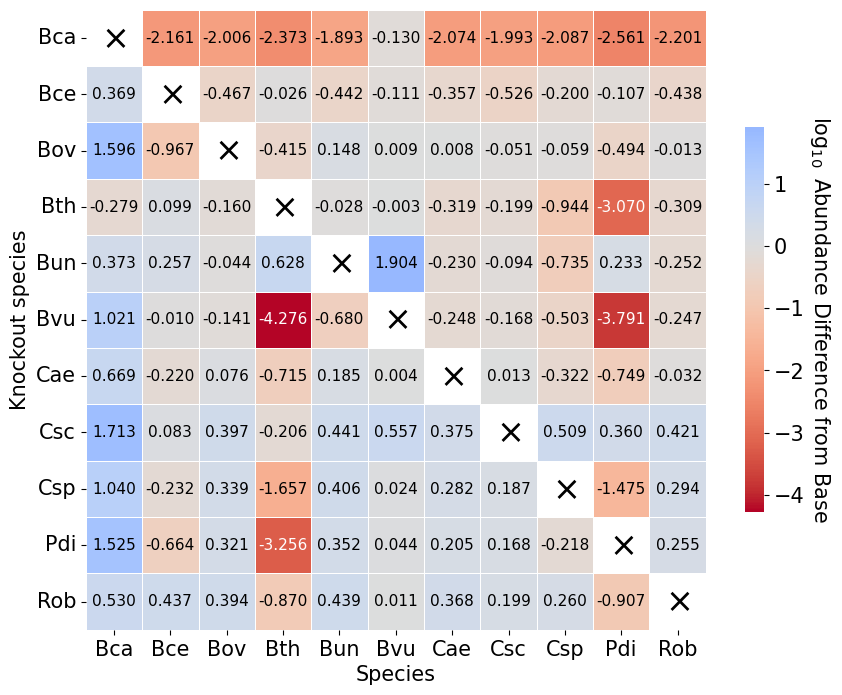

In [5]:
mask = ko_log_foldchange_mean.isna()
plt.rc('font', size=15)
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
plt.figure(figsize=(10,10))
ax = sns.heatmap(
    ko_log_foldchange_mean, 
    cmap=cmap, 
    mask=mask, 
    center=0, 
    square=True, 
    cbar_kws={"shrink": .5}, 
    linewidths=0.5,
    linecolor='w',
    # annot=True,
    # fmt='.3f',
    annot_kws={'size': 11}
    )
for i in range(mask.shape[0]):
    for j in range(mask.shape[1]):
        if mask.iloc[i,j] == True:
            plt.text(j+0.5, i+0.5, '$\\times$', ha='center', va='center', color='k', fontsize=24)
        else:
            if np.abs(ko_log_foldchange_mean.iloc[i,j]) > 3:
                plt.text(j+0.5, i+0.5, f'{ko_log_foldchange_mean.iloc[i,j]:.3f}', ha='center', va='center', color='w', fontsize=11)
            else:
                plt.text(j+0.5, i+0.5, f'{ko_log_foldchange_mean.iloc[i,j]:.3f}', ha='center', va='center', color='k', fontsize=11)
cbar = ax.collections[0].colorbar
cbar.set_label('$\log_{10}$ Abundance Difference from Base', rotation=270, fontsize=15, labelpad=20)
ax.set_xticklabels(ax.get_xticklabels(), ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
plt.savefig("results/hf0/knockouts/ko_foldchange_mean.svg", bbox_inches='tight', dpi=300)
plt.show()